# Task 1: Preparing the data

> **This is the solution notebook.** Every `# TODO` is filled in and every question has a model answer. The student version is `task_1_preprocess.ipynb`.

In this task you'll take the raw power-flow data and turn it into a clean, hourly time series that a forecasting model can use. Task 2 starts from the file you save at the end.

**By the end you should have:**

- a file `data/forecast_preproc_task.csv` with three columns (`Timestamp`, `Demand`, `Import`) and one row per hour;
- a short explanation, in your own words, of each step you took and why.
- You can compare your .csv to `data/forecast_preproc.csv` to confirm your solution is ready.

**How this notebook works**

- Read the text, then run each cell in order (Shift + Enter).

Run the notebook from the project folder (the one that contains `data/`).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Step 1: Load the data

The raw data is in `data/Forecasting_dataset.csv`. It has a reading every 5 minutes for six quantities: `Demand`, `Generation`, `Import`, `Solar`, `Wind` and `Other`. We only forecast **Demand** and **Import**.

**Watch the dates.** The timestamps are written day first, so `01/12/2020` means 1 December. We tell pandas this with `dayfirst=True`. Without it, pandas may silently read the date as 12 January.

In [2]:
data = pd.read_csv('data/Forecasting_dataset.csv')
data['Timestamp'] = pd.to_datetime(data['Timestamp'], dayfirst=True)
data = data.set_index('Timestamp')
data.head()

,Demand,Generation,Import,Solar,Wind,Other
Timestamp,,,,,,
2020-12-01 00:00:00,7620.20,931.99,6693.61,32.56,533.19,353.10
2020-12-01 00:05:00,7735.67,990.75,6749.23,32.35,521.96,366.60
2020-12-01 00:10:00,7771.58,995.03,6779.92,32.45,511.67,368.03
2020-12-01 00:15:00,7792.93,992.68,6802.93,32.39,515.04,366.12
2020-12-01 00:20:00,7749.35,945.33,6807.54,32.45,517.15,359.86


Print how many rows there are, and the first and last timestamp.

In [3]:
print('Rows:', len(data))
print('First timestamp:', data.index.min())
print('Last timestamp :', data.index.max())

Rows: 31680
First timestamp: 2020-12-01 00:00:00
Last timestamp : 2021-03-21 23:55:00


**Question 1.** Roughly how many weeks of data is this? At one reading every 5 minutes, about how many rows would you expect? Keep this in mind for step 3.

*Answer:* The data runs from 1 Dec 2020 to 21 Mar 2021, about **16 weeks** (112 days). At 12 readings an hour that's `112 * 24 * 12 =` about **32,000** rows. The file has 31,680, so a few hundred are missing: the subject of step 3.

*Your answer:*

## Step 2: Look before you clean

Always plot the data before changing it. Every cleaning step later in this notebook should be justified by something you can see here.

Plot `Demand` and `Import` against time on the same axes. Give each a `label`, add a title and axis labels, and call `ax.legend()`.

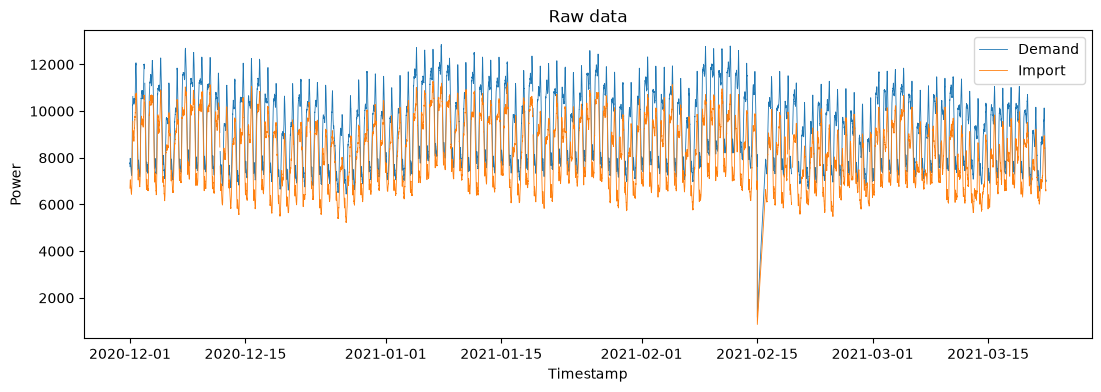

In [4]:
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(data.index, data['Demand'], label='Demand', linewidth=0.6)
ax.plot(data.index, data['Import'], label='Import', linewidth=0.6)
ax.set_title('Raw data')
ax.set_xlabel('Timestamp')
ax.set_ylabel('Power')
ax.legend()
plt.show()

**Question 2.** Describe what you see.

- Is there a daily pattern? A weekly one?
- Does anything look physically implausible?

*Answer:* Both series show a strong **daily** cycle (low overnight, peaks in the day) and a **weekly** one (weekends sit lower than weekdays). Demand runs a bit above Import throughout. One point drops almost to zero around mid-February, which is not physically plausible for a whole region, so it's a fault to deal with later.

*Your answer:*

## Step 3: Find the missing data

Missing data comes in two kinds, and a plot like the one above hides both:

1. **Blank values.** The timestamp is in the file but the value is empty. pandas reads these as `NaN`. matplotlib leaves a break in the line, but a short break is far too narrow to see over three and a half months. (You can also see these easily by opening the .csv file directly.)
2. **Missing rows.** The timestamp isn't in the file at all. matplotlib draws a straight line across the gap, so it's invisible too.

Start with blank values. Count how many there are in `Demand` and `Import`.

In [5]:
print(data[['Demand', 'Import']].isna().sum())

Demand    95
Import    95
dtype: int64


To find missing rows, compare the data with a perfect 5-minute grid running from the first timestamp to the last. `pd.date_range` builds that grid for us.

In [6]:
expected_index = pd.date_range(start=data.index.min(), end=data.index.max(), freq='5min')

n_missing_rows = len(expected_index) - len(data)
print('Missing rows:', n_missing_rows)

Missing rows: 288


In [7]:
# Check (don't edit me)
assert n_missing_rows is not None, 'Set n_missing_rows in the cell above.'
assert n_missing_rows == 288, f'Got {n_missing_rows}. Check which length you subtract from which.'
print('Looks good.')

Looks good.


Now find *where* the missing data is.

- For the **missing rows**, the gap between one timestamp and the next is more than 5 minutes. `data.index.to_series().diff()` gives the gap before each row; find the rows where it's bigger than `pd.Timedelta('5min')`.
- For the **blank values**, count the `NaN`s per calendar day. Group `data['Demand'].isna()` by `data.index.date` and sum. Show only the days that have some.

In [8]:
# Missing rows: where the step between timestamps is more than 5 minutes
step = data.index.to_series().diff()
print('Missing rows:')
print(step[step > pd.Timedelta('5min')])

# Blank values per day (only days that have some)
blanks_per_day = data['Demand'].isna().groupby(data.index.date).sum()
print('\nBlank values per day:')
print(blanks_per_day[blanks_per_day > 0])

Missing rows:
Timestamp
2021-02-16 00:45:00   1 days 00:05:00
Name: Timestamp, dtype: timedelta64[us]

Blank values per day:
2020-12-01    19
2020-12-02    12
2020-12-11    12
2021-01-18    10
2021-02-18     6
2021-02-19    36
Name: Demand, dtype: int64


Zoom in on the week with the most missing data. Each dot is one reading. Plot `Demand` for 14 to 20 February 2021 with `marker='.'` so individual readings show up.

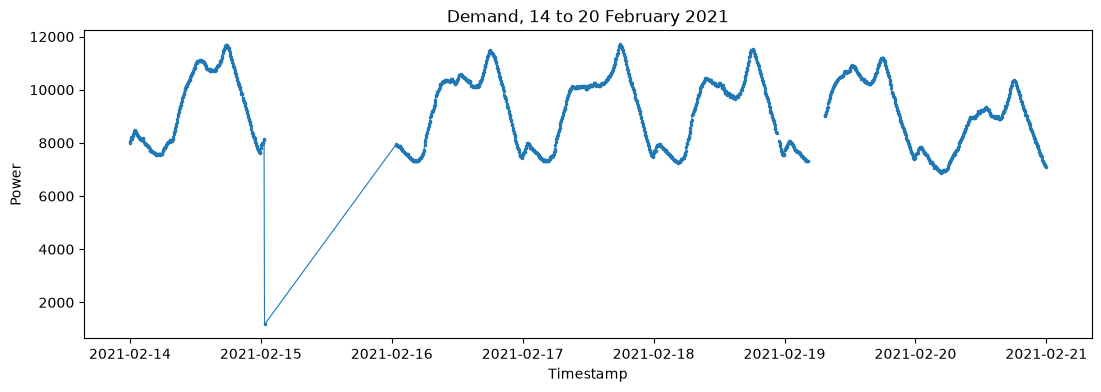

In [9]:
window = data.loc['2021-02-14':'2021-02-20']
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(window.index, window['Demand'], marker='.', markersize=3, linewidth=0.8)
ax.set_title('Demand, 14 to 20 February 2021')
ax.set_xlabel('Timestamp')
ax.set_ylabel('Power')
plt.show()

**Question 3.**

- Where is the longest stretch of missing data, and how long is it?
- In the zoomed plot, how does matplotlib draw the missing rows? How does it draw the blank values? Why is the first one misleading?

*Answer:* The longest stretch is the **missing rows** from 15 Feb 00:40 to 16 Feb 00:45, about **24 hours** (288 readings). The **blank values** are shorter, up to 3 hours. In the zoomed plot the missing rows are drawn as a straight line that connects across the gap, while the blank values leave a visible break. The straight line is misleading because it looks like real, smooth data when nothing was actually recorded.

*Your answer:*

## Step 4: Put the data on a regular grid

Time-series models assume one row for every time step, evenly spaced. With rows missing, the model can't tell that a day has passed between two neighbouring rows.

The fix is to `reindex` the data onto the `expected_index` grid from step 3. Timestamps that were missing come back as rows full of `NaN`. The gap is now explicit instead of hidden.

In [10]:
data = data.reindex(expected_index)
data.index.name = 'Timestamp'

print('Rows now:', len(data))
print('NaNs per column:')
print(data[['Demand', 'Import']].isna().sum())

Rows now: 31968
NaNs per column:
Demand    383
Import    383
dtype: int64


In [11]:
# Check (don't edit me)
assert len(data) == 31968, f'Expected 31968 rows on the full grid, got {len(data)}.'
assert pd.infer_freq(data.index) == '5min', 'Timestamps should now be exactly 5 minutes apart.'
assert (data[['Demand', 'Import']].isna().sum() == 383).all(), 'Each column should have 383 NaNs (288 missing rows + 95 blanks).'
print('Looks good.')

Looks good.


**Question 4.** How many `NaN`s does each column have now? Explain where that number comes from, using your answers from step 3.

*Answer:* **383** per column. That's the **288 missing rows** (now filled with `NaN` by the reindex) plus the **95 blank values** that were already `NaN` in the file.

*Your answer:*

## Step 5: Remove the fault

In step 2 you may have spotted a reading that drops to a fraction of its normal level. It's at **2021-02-15 00:40**, five minutes before the 24-hour outage starts, so it's almost certainly the same equipment fault. A model trained on it would try to explain it, which would distort the forecast.

We'll use a simple rule: a value is an **outlier** if it is at least **4 standard deviations** from the column's mean:

$$|x - \mu| \ge 4\sigma$$

We set outliers to `NaN` rather than deleting the row. That keeps the grid regular, and the value is treated as missing, like the gaps.

In [12]:
for column in ['Demand', 'Import']:
    mean = data[column].mean()
    std = data[column].std()
    mask = (data[column] - mean).abs() >= 4 * std
    print(f'{column}: removing {int(mask.sum())} outlier(s)')
    data.loc[mask, column] = np.nan

Demand: removing 1 outlier(s)
Import: removing 1 outlier(s)


In [13]:
# Check
fault = pd.Timestamp('2021-02-15 00:40')
assert data.loc[fault, ['Demand', 'Import']].isna().all(), 'The fault reading at 2021-02-15 00:40 is still there.'
assert (data[['Demand', 'Import']].isna().sum() == 384).all(), (
    'Each column should have exactly one more NaN than in step 4. Did you remove too much, or too little?')
print('Looks good.')

Looks good.


**Question 5.**

- The tallest peaks in the raw plot (around 12,850) were *not* removed. Why is that the right outcome?
- The mean and standard deviation were calculated from all the data, *including* the fault. Why could this rule struggle on a dataset with many faults, or with a fault that lasts for hours?

*Answer:* The tall peaks are **real** evening demand peaks, within 4 standard deviations of the mean, so keeping them is correct: we only want to drop the implausible drop. The rule is weak because the mean and standard deviation are themselves affected by the bad data: many faults, or a long one, would inflate the standard deviation and pull the mean, so genuine outliers would no longer look like outliers. More robust rules use the median and MAD, or a rolling window.

*Your answer:*

## Step 6: Experiment. Should we fill the gaps?

> **This step is an experiment.** You'll try a common technique, judge the result, and then decide whether to keep it.

**Interpolation** fills each `NaN` using the values around it. *Linear* interpolation draws a straight line from the last known value before a gap to the first known value after it. Many models (most of scikit-learn, neural networks) can't accept `NaN`s, so this is a very common step.

Try it on a **copy** of the data, so the main `data` isn't changed.

In [14]:
data_interp = data.copy()
data_interp = data_interp.interpolate(method='linear', limit_area='inside')

Compare the two versions on a long gap and on a short one. Orange shows where interpolation filled in values.

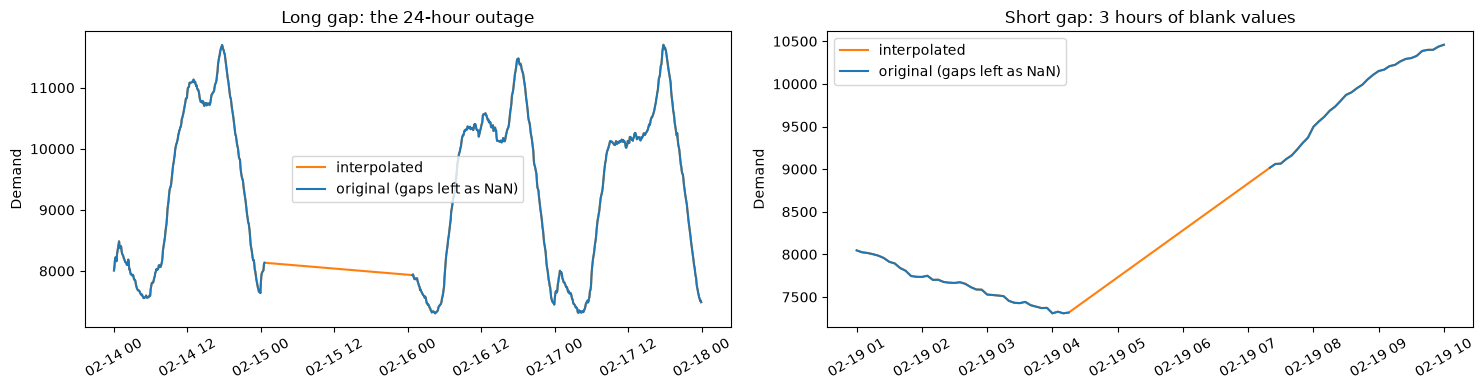

In [15]:
windows = [('2021-02-14', '2021-02-17', 'Long gap: the 24-hour outage'),
           ('2021-02-19 01:00', '2021-02-19 10:00', 'Short gap: 3 hours of blank values')]
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
for ax, (start, end, title) in zip(axes, windows):
    ax.plot(data_interp.loc[start:end, 'Demand'], color='tab:orange', label='interpolated')
    ax.plot(data.loc[start:end, 'Demand'], color='tab:blue', label='original (gaps left as NaN)')
    ax.set_title(title)
    ax.set_ylabel('Demand')
    ax.tick_params(axis='x', rotation=30)
    ax.legend()
plt.tight_layout()
plt.show()

**Question 6.**

1. Does interpolation make the data look **better or worse**? Answer separately for the short gap and the long gap.
2. What are the **pros** of filling gaps this way?
3. What are the **cons**? Think about what a model would learn from a straight line drawn across a full day of demand.
4. Is there a gap length beyond which you'd stop trusting interpolation? Roughly what length, and why?

*Answer:*
1. For the **short gap** it looks fine: over a few hours a straight line is a reasonable guess. For the **long gap** it looks clearly **worse**: a flat diagonal line replaces a whole day that should have had two peaks and a trough.
2. **Pros:** gives a complete, gap-free series that any model can accept, and it's quick and simple.
3. **Cons:** it invents data. A model would learn a straight ramp where a full daily cycle belongs, which is just wrong, and it hides the fact that the data was missing.
4. A rough rule: trust it while the gap is short compared with the main cycle (here, well under a day). Once the gap spans a full cycle or more, a straight line can't capture the shape and interpolation does more harm than good.

*Your answer:*

### Our decision for this task: don't interpolate

The model we use in Task 2, **SARIMAX**, doesn't need gap-free data. Roughly speaking, it steps through the series one time step at a time, updating its estimate of what's going on at each step. When it meets a `NaN`, it skips the update and carries its own prediction forward. So we can leave the gaps as they are, rather than inventing a day of data.

**From here on, carry on with `data`, not `data_interp`.** If you later use a model that can't handle `NaN`s, this is the step to revisit.

## Step 7: Downsample to hourly

At 5-minute resolution there are about 32,000 rows. For a week-ahead forecast that's far more detail than we need, and it makes the model slow to fit. Hourly data keeps the daily and weekly shape and is 12 times smaller.

There are two reasonable ways to do this:

- **Option A:** keep the reading taken on the hour, with `data.iloc[::N]` (every Nth row). How many 5-minute readings are there in an hour?
- **Option B:** average each hour, with `data.resample('h').mean()`.

Either is fine. Say which you chose, and why, in your summary at the end.

In [16]:
# Option A: keep the reading on the hour (every 12th 5-minute row)
data_hourly = data.iloc[::12]
print('Rows after downsampling:', len(data_hourly))

Rows after downsampling: 2664


In [17]:
# Check
assert data_hourly is not None, 'Set data_hourly in the cell above.'
assert len(data_hourly) == 2664, f'Expected one row per hour (2664 rows), got {len(data_hourly)}.'
assert pd.infer_freq(data_hourly.index) in ('h', 'H'), 'Timestamps should be exactly one hour apart.'
print('Looks good.')

Looks good.


**Question 7.** The fault reading was at 00:40.

- With option A, would the fault have made it into the hourly data anyway? With option B?
- Why is it still good practice to remove outliers *before* downsampling?

*Answer:* With **option A** we keep only the reading on the hour (00:00), so the 00:40 fault would be dropped by the downsampling anyway. With **option B** the whole hour is averaged, so the fault would pull the 00:00 hourly average down unless we'd already removed it. Removing outliers first is good practice because it protects any averaging step, and it means the pipeline still works if you later switch option, change the sampling rate, or meet a fault that does land on the hour.

*Your answer:*

## Step 8: Save the result

Keep only the `Demand` and `Import` columns of `data_hourly` and save them as a CSV. Task 2 reads this file.

Remember: save the version with the gaps left as `NaN`, not the interpolated one.

In [18]:
OUTPUT_PATH = 'data/forecast_preproc_task.csv'
data_hourly[['Demand', 'Import']].to_csv(OUTPUT_PATH)

In [19]:
# Check
saved = pd.read_csv(OUTPUT_PATH, index_col='Timestamp', parse_dates=True)
assert list(saved.columns) == ['Demand', 'Import'], f'Expected columns Demand and Import, got {list(saved.columns)}.'
assert len(saved) == 2664, f'Expected 2664 hourly rows, got {len(saved)}.'
assert pd.infer_freq(saved.index) in ('h', 'H'), 'Timestamps should be one hour apart.'
assert saved.isna().sum().sum() > 0, (
    'There are no gaps at all. Did you save the interpolated data? SARIMAX handles NaNs, so keep them.')
print('Saved and checked. You are ready for Task 2.')

Saved and checked. You are ready for Task 2.


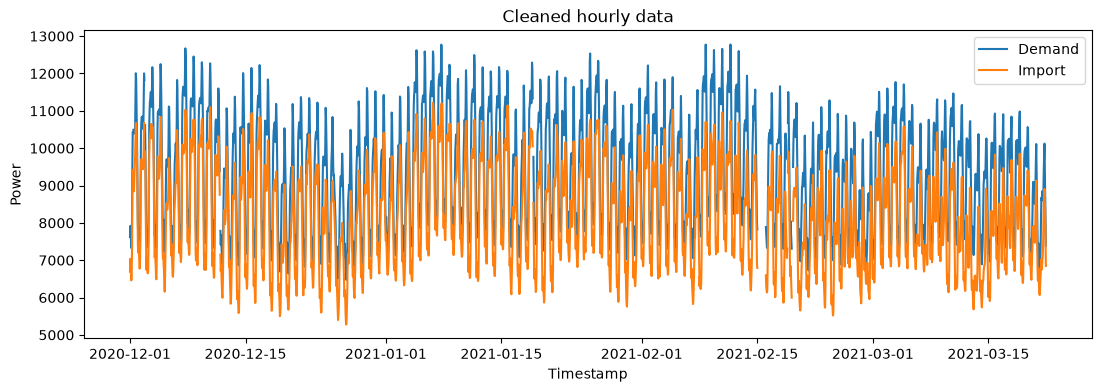

In [20]:
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(saved.index, saved['Demand'], label='Demand')
ax.plot(saved.index, saved['Import'], label='Import')
ax.set_title('Cleaned hourly data')
ax.set_xlabel('Timestamp')
ax.set_ylabel('Power')
ax.legend()
plt.show()

## Step 9: Explain what you did

Compare the cleaned plot with the raw one from step 2. Then fill in the table below, in your own words. Aim for one or two sentences per cell: someone who hasn't seen this notebook should understand what you did and why.

| Step | What I did | Why |
|---|---|---|
| Load the data | Read the CSV, parsed the day-first timestamps, set them as the index. | Get a time-indexed series pandas can work with. |
| Look at the raw data | Plotted Demand and Import over the full period. | Spot the patterns and problems before changing anything. |
| Find the missing data | Counted blank values and missing rows, and found where they are. | Know what and how much needs fixing. |
| Regular grid | Reindexed onto a complete 5-minute grid. | Give the model evenly spaced steps; make gaps explicit NaNs. |
| Remove the fault | Set values more than 4 std from the mean to NaN. | Stop one implausible reading distorting the model. |
| Interpolation (tried) | Linearly interpolated a copy and compared. | Decided against it: SARIMAX handles NaNs and it invents a day of data. |
| Downsample | Kept the reading on each hour (option A). | 12x fewer rows while keeping the daily/weekly shape; faster to fit. |
| Save | Wrote Demand and Import to forecast_preproc_task.csv. | Hand a clean hourly series to Task 2. |

**Question 8.** Beyond the data you were given, what other datasets or outside factors might help forecast demand and import? Think about what makes people use more or less electricity, and what affects how much is generated locally.

*Answer:* **Weather** is the big one: temperature drives heating and cooling, while wind speed and sunshine drive local wind and solar generation (and so change how much has to be imported). **Calendar** effects help too: public holidays, school terms, and the difference between weekdays and weekends. Other useful signals include electricity price, big televised events, and longer-term economic activity.

*Your answer:*